# Cost case study — an LRMP that takes 160× an LRM

A report from the forum:

> I am comparing two very similar models, one with LRM, the other one with LRMP. Both simulate a batch-elution process for a 2-component system with a linear isotherm. For validation purposes [...] rapid equilibrium, non-limiting film diffusion ($k_f = 1$), and no axial dispersion. While the LRM completes within a few seconds, the LRMP takes approximately 20 minutes to run under the same conditions.

It reproduces. On the current build, rebuilt on the `COLUMN_MODEL_1D` interface, the LRM takes **about 2 s** and the LRMP **about 315 s**.

**The answer, up front.** It is not stiffness, not the physics, and not the extra unknowns. It is one solver parameter. The LRMP routes to a linear solver that asks an **unpreconditioned GMRES** for eight digits it does not need, and loosening that single tolerance by two decades recovers a **factor of 35 while changing the answer in no digit at all**.

This notebook belongs with the stiffness chapter as its counterpoint: everything there concluded that cost comes from accuracy, never from stability. Here is a third thing, which is neither.

## The two models

Set up to be the same problem, which is the whole premise of the comparison.

| | LRM | LRMP |
|---|---|---|
| porosity | total 0.72 | bed 0.3 × particle 0.6 = the same 0.72 |
| binding | linear, rapid equilibrium | identical |
| axial dispersion | 0 | 0 |
| film | — | $k_f = 1$ m/s at $r_p$ = 5 µm |
| grid | 500 FV cells, WENO | identical |

$k_f = 1$ m/s is not a physical film coefficient. It is a deliberately enormous one, chosen so the pore liquid is pinned to the bulk liquid and the LRMP *reduces* to the LRM. At $r_p$ = 5 µm it makes the film rate

$$\frac{3 k_f}{r_p}\cdot\frac{1-\varepsilon_c}{\varepsilon_c} \approx 1.4\cdot10^{6}\ \mathrm{s^{-1}},$$

against convection across one of 500 cells at about $6\ \mathrm{s^{-1}}$.

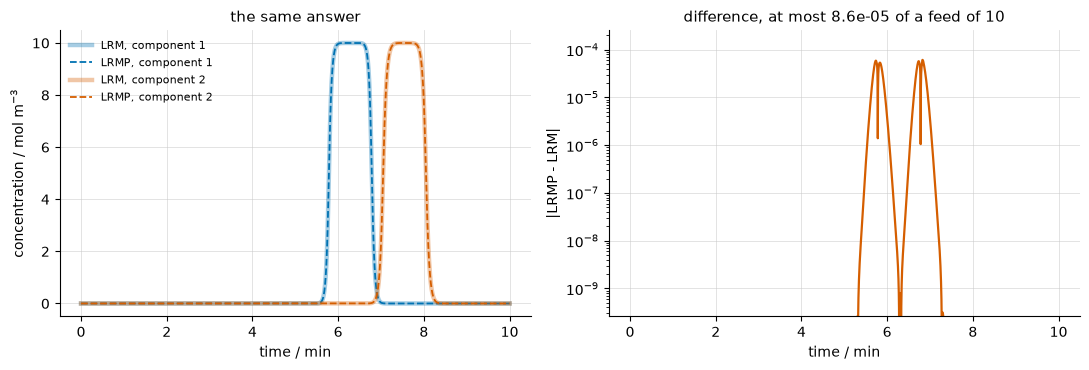

In [1]:
import utility.lrmp_cost_explorer as study

study.plot_same_problem();

The two chromatograms agree to about $10^{-5}$ of a feed of 10. **So whatever costs 160× is not producing a different answer** — it is numerics, not physics.

The chapter's instinct at this point is stiffness: a process at $1.4\cdot10^{6}\ \mathrm{s^{-1}}$ next to one at $6\ \mathrm{s^{-1}}$ is a classic stiff pair. So look at what the time integrator did.

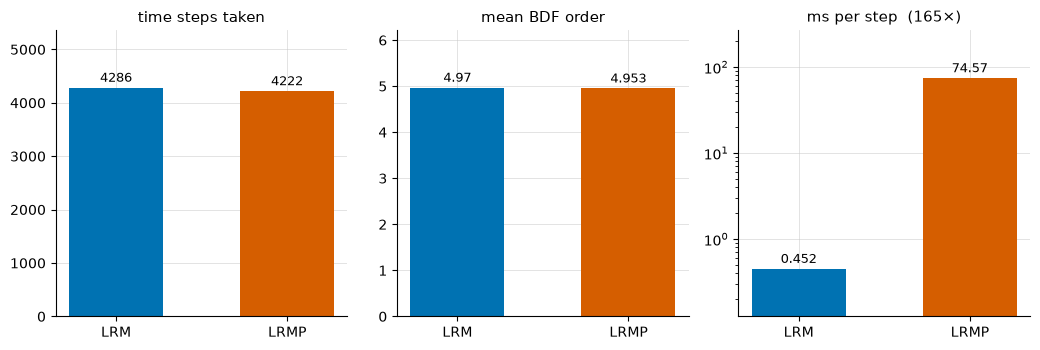

In [2]:
study.plot_where_the_time_goes();

**It is not stiffness.** The LRMP takes *fewer* time steps than the LRM, at the same BDF order. The integrator behaved identically; the error control never noticed anything. The entire gap is **cost per step**.

Nor is it size: the LRMP has 3000 unknowns against the LRM's 2000, a factor of 1.5 against a factor of 167 in cost per step.

So the question becomes: what inside a single step costs 75 ms for a 3000-unknown banded system? Sweep the film coefficient and watch.

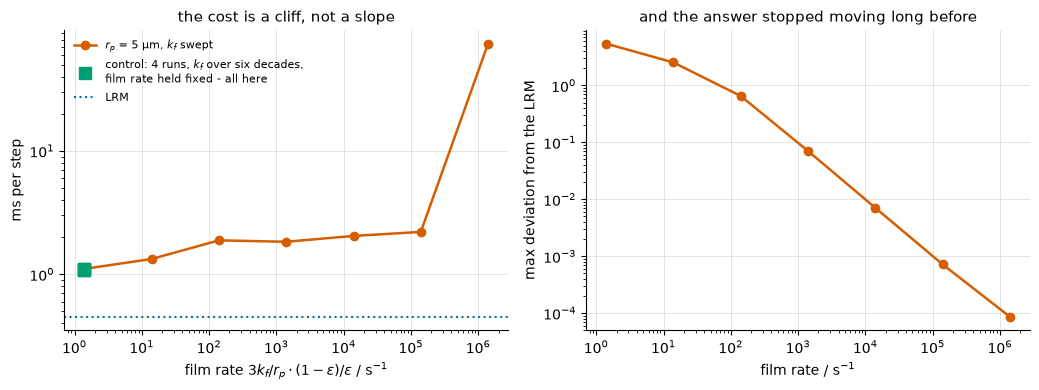

In [3]:
study.plot_the_cliff();

Two things to read here, and both were surprises.

**It is a cliff, not a slope.** Six decades of film coefficient cost essentially nothing — 1.2 to 2.2 ms per step — and then the last decade costs 75. A gradual loss of conditioning would have shown a gradual price. This does not.

**It is the rate, not the coefficient.** The square markers hold the film *rate* fixed at 1.4 s⁻¹ while raising $k_f$ by six decades and $r_p$ with it. They are flat. A large $k_f$ is harmless on its own; what matters is $3k_f/r_p$.

**And the right panel is the practical point.** The answer stops moving at a film rate of about $10^{4}\ \mathrm{s^{-1}}$. Everything past that is paying for digits that are already converged — and the cliff is two decades beyond *that*.

## What is actually happening

From the source (`b5803775`), four facts that compose into the cliff:

1. **`ColumnModelBuilder.cpp`** — with an FV bulk *and* an FV particle, `FV_ARROW_HEAD_OPTIMIZATION` defaults to **true**, routing the LRMP to the legacy block-structured unit operation rather than to `ColumnModel1D`'s global sparse solver.
2. **`LumpedRateModelWithPores-LinearSolver.cpp`** — that path eliminates the particle unknowns into a **Schur complement** and solves it iteratively. The LRM has no particle unknowns, so no Schur complement and no iteration: it goes straight to a direct factorization. *That* is the structural difference between the two models.
3. **`Gmres.cpp:80`** — the iterative solver is `SUNLinSol_SPGMR(..., SUN_PREC_NONE, ...)`: **GMRES with no preconditioner**. Its iteration count is therefore at the mercy of the Schur complement's conditioning, which the film coupling sets. With `MAX_KRYLOV = 0` the Krylov dimension may grow to the full system size (`Gmres.cpp:70`), and Gram–Schmidt orthogonalization costs $\mathcal{O}(k^2 n)$ — so an iteration count that goes from ten to a few hundred raises the cost superlinearly. **That is the cliff.**
4. **`LumpedRateModelWithPores-LinearSolver.cpp:242`** — the tolerance it must reach is `sqrt(nDof) · outerTol · SCHUR_SAFETY`, and `SCHUR_SAFETY` defaults to **1e-8**.

Point 4 is the one worth testing, because it is the only one that is a free choice.

,how the linear system is solved,wall clock / s,vs LRM,steps,max deviation from LRM
0,"arrow head, SCHUR_SAFETY 1e-8 (default)",314.82,162.5,4222,8.636e-05
1,"arrow head, SCHUR_SAFETY 1e-6",8.81,4.5,4222,8.636e-05
2,"arrow head, SCHUR_SAFETY 1e-4",7.98,4.1,4222,8.636e-05
3,"arrow head, SCHUR_SAFETY 1e-2",7.62,3.9,4313,8.643e-05
4,"arrow head, MAX_KRYLOV 100",17.57,9.1,4222,8.636e-05
5,global sparse solver,7.03,3.6,4524,9.757e-05


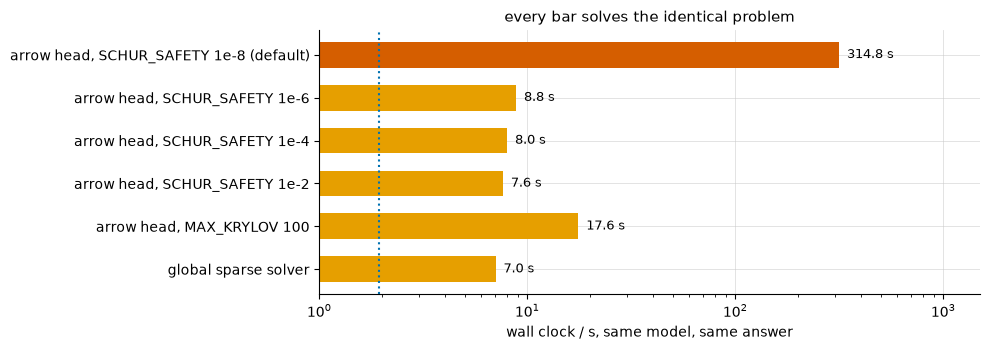

In [4]:
study.plot_the_fixes()
study.summary()

**Every row above is the same model and returns the same answer.** The deviation column is the check: loosening `SCHUR_SAFETY` from 1e-8 to 1e-6 changes the result in **no digit at all** and costs 35× less. The 313 seconds bought nothing.

Capping the Krylov dimension helps too, and for the predicted reason — it bounds the $\mathcal{O}(k^2)$ orthogonalization — but less than simply not demanding the digits. Routing to the global sparse solver is fastest of all, because a direct factorization does not care about conditioning.

The residual factor of ~4 over the LRM is honest: the LRMP really does have a particle phase to solve for.

### If you hit this

1. **Do not use a film coefficient far past the point where the answer converged.** The right panel above says $10^{4}\ \mathrm{s^{-1}}$ was already enough; the reported setting is two decades beyond the cliff. If you want an LRMP to behave like an LRM, use an LRM.
2. **`SCHUR_SAFETY = 1e-6`** — one line, 35×, identical answer.
3. **`FV_ARROW_HEAD_OPTIMIZATION = 0`** — routes to the global direct sparse solver, which has no iterative tolerance to tune.

### For CADET-Core

The default is fragile in a way a user cannot see: `SCHUR_SAFETY = 1e-8` on an **unpreconditioned** GMRES makes the cost of a perfectly well-posed model depend on a coupling coefficient, with a cliff rather than a warning. Worth considering: preconditioning the Schur complement, scaling the tolerance to the problem, capping `MAX_KRYLOV` by default, or preferring the global sparse solver for FV+FV.

> **Take-away.** The stiffness chapter found that cost comes from accuracy, never from stability. This is a third source and it belongs on the list: **the cost of the linear solve inside each step**, which no step count, BDF order or error-test counter will reveal. When a model is slow and the integrator looks healthy, look below it.